# 05 · La maceta y la semilla

Mientras la flor industrial desaparecía, creció otra forma de vender cempasúchil: la **planta en maceta**, sobre todo en Xochimilco, Tláhuac y el Estado de México. Y con ella llegó la semilla híbrida importada, que la prensa llama "cempasúchil chino" aunque viene sobre todo de Estados Unidos: la flor que México prestó al mundo vuelve como semilla.

In [1]:
import sys
from pathlib import Path

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ))

import pandas as pd
import plotly.graph_objects as go

from src import config, tema

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 160)

estatal = pd.read_csv(config.DIR_PROCESSED / "cempasuchil_estatal.csv")
municipal = pd.read_csv(config.DIR_PROCESSED / "cempasuchil_municipal.csv")
FUENTE_SIAP = "Fuente: SIAP, Cierre de la Producción Agrícola 1980-2025. Análisis: Sahuaris."

In [2]:
plantas = estatal[estatal["presentacion"] == "Planta en maceta"]
p_anual = plantas.pivot_table(index="anio", columns="nomestado", values="volumenproduccion", aggfunc="sum").fillna(0)
p_anual["total"] = p_anual.sum(axis=1)
p_anual.astype(int)

nomestado,Ciudad de México,Ciudad de México / DF,México,Tlaxcala,total
anio,,,,,
2005,0,0,360000,0,360000
2006,0,0,720000,0,720000
2007,0,222000,696000,0,918000
2008,0,250000,461500,0,711500
2009,0,250000,468000,0,718000
2010,0,300000,540195,0,840195
2011,0,330000,720100,0,1050100
2012,0,0,720000,0,720000
2013,0,901000,810000,24000,1735000


In [3]:
p05 = p_anual.loc[2005, "total"]
p25 = p_anual.loc[2025, "total"]
print(f"Plantas en maceta (SIAP): {p05:,.0f} en 2005 -> {p25:,.0f} en 2025 ({p25 / p05:.1f} veces)")
print(f"Pico SIAP: {int(p_anual['total'].idxmax())} con {p_anual['total'].max():,.0f}")

Plantas en maceta (SIAP): 360,000 en 2005 -> 3,021,200 en 2025 (8.4 veces)
Pico SIAP: 2024 con 3,163,428


## El SIAP se queda corto

El gobierno de la CDMX reporta muchas más plantas que el SIAP para la misma ciudad. Las dos fuentes miden cosas parecidas pero no iguales: Sedema cuenta lo que producen los viveros apoyados por la ciudad, y el SIAP lo que registran los distritos de desarrollo rural.

In [4]:
doc = pd.read_csv(config.DIR_MANUAL / "cifras_documentales.csv").set_index("id")
sedema = pd.Series({2018: doc.loc["cdmx_plantas_2018", "valor"], 2025: doc.loc["cdmx_plantas_2025", "valor"], 2026: doc.loc["cdmx_plantas_2026", "valor"]})
siap_cdmx = p_anual.get("Ciudad de México", pd.Series(dtype=float))
comparacion = pd.DataFrame({"SIAP (CDMX)": siap_cdmx.reindex(sedema.index), "Sedema / gobierno CDMX": sedema})
comparacion["veces"] = (comparacion["Sedema / gobierno CDMX"] / comparacion["SIAP (CDMX)"]).round(1)
comparacion

,SIAP (CDMX),Sedema / gobierno CDMX,veces
2018,1333200.0,664000,0.5
2025,1952000.0,6300000,3.2
2026,NaN,9924300,NaN


Interactiva: outputs/figuras/05_plantas_maceta.html


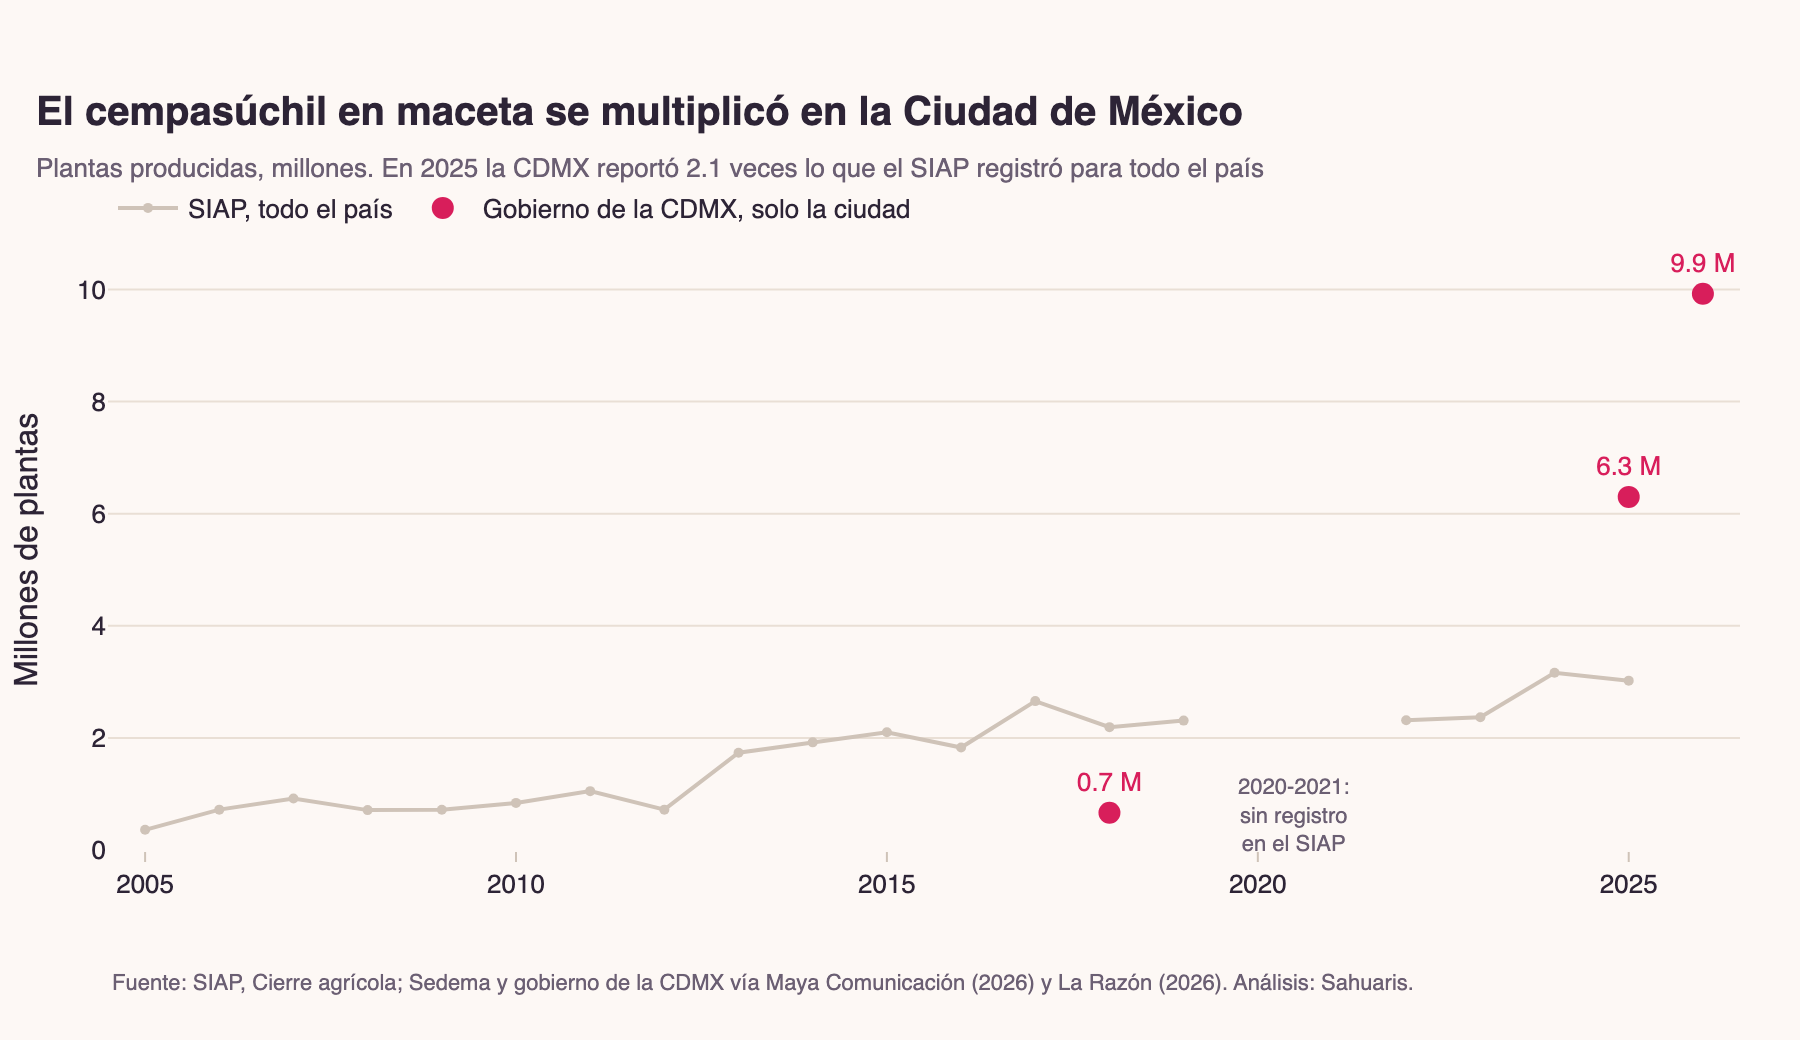

In [5]:
fig = go.Figure()
serie = p_anual["total"].reindex(range(2005, 2026))
fig.add_trace(go.Scatter(x=serie.index, y=serie.values / 1e6, name="SIAP, todo el país", mode="lines+markers",
                         line=dict(color=tema.NEUTRO, width=2), marker=dict(size=5), connectgaps=False,
                         hovertemplate="%{x}: %{y:.2f} millones<extra>SIAP</extra>"))
fig.add_trace(go.Scatter(x=sedema.index, y=sedema.values / 1e6, name="Gobierno de la CDMX, solo la ciudad", mode="markers+text",
                         marker=dict(color=tema.PROTAGONISTA, size=11), text=[f"{v / 1e6:.1f} M" for v in sedema.values],
                         textposition="top center", textfont=dict(color=tema.PROTAGONISTA),
                         hovertemplate="%{x}: %{y:.2f} millones<extra>CDMX</extra>"))
fig.add_annotation(x=2020.5, y=0.6, text="2020-2021:<br>sin registro<br>en el SIAP", showarrow=False, font=dict(size=11, color=tema.TEXTO_SUAVE))
fig.update_layout(
    title=tema.titulo("El cempasúchil en maceta se multiplicó en la Ciudad de México",
                      f"Plantas producidas, millones. En 2025 la CDMX reportó {sedema.loc[2025] / p_anual.loc[2025, 'total']:.1f} veces lo que el SIAP registró para todo el país"),
    xaxis=dict(title="", range=[2004.5, 2026.5]), yaxis=dict(title="Millones de plantas", rangemode="tozero"), height=520,
)
tema.nota_fuente(fig, "Fuente: SIAP, Cierre agrícola; Sedema y gobierno de la CDMX vía Maya Comunicación (2026) y La Razón (2026). Análisis: Sahuaris.")
tema.mostrar(fig, "05_plantas_maceta", alto=520)

## La semilla que regresa

No hay estadística oficial de semilla importada. Lo más sólido es la declaración del Consejo Mexicano de la Flor (99 % de la semilla de maceta es importada); lo demás son estimaciones de agrónomos y precios levantados por reporteros:

In [6]:
doc.loc[["semilla_maceta_importada_pct", "semilla_importada_pct", "precio_maceta_importada_min", "precio_maceta_importada_max",
         "precio_maceta_criolla_min", "precio_maceta_criolla_max"], ["afirmacion", "valor", "unidad", "fuente"]]

,afirmacion,valor,unidad,fuente
id,,,,
semilla_maceta_importada_pct,Porcentaje de la semilla de cempasúchil en mac...,99,%,Imagen Agropecuaria
semilla_importada_pct,Porcentaje de plantas de cempasúchil en México...,50,%,"Yahoo Noticias / El Sabueso (Gael Manceras, ag..."
precio_maceta_importada_min,Precio mínimo de planta de semilla importada,15,pesos,Yahoo Noticias / El Sabueso
precio_maceta_importada_max,Precio máximo de planta de semilla importada,30,pesos,Yahoo Noticias / El Sabueso
precio_maceta_criolla_min,Precio mínimo de planta de semilla criolla,50,pesos,Yahoo Noticias / El Sabueso
precio_maceta_criolla_max,Precio máximo de planta de semilla criolla,150,pesos,Yahoo Noticias / El Sabueso


In [7]:
p_anual.to_csv(config.DIR_PROCESSED / "plantas_maceta.csv")